In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [3]:
df = pd.read_csv("../data/Mall_Customers.csv")

df.rename(columns={
    "Genre":"Gender",
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Score"
}, inplace=True)

df.head()

,CustomerID,Gender,Age,Income,Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
conn = sqlite3.connect("customer_segmentation.db")

df.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

print("Database Created Successfully!")

Database Created Successfully!


In [5]:
query = """
SELECT *
FROM customers
LIMIT 10;
"""

pd.read_sql(query, conn)

,CustomerID,Gender,Age,Income,Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


**Basic SQL Queries**

In [6]:
query = """
SELECT COUNT(*) AS Total_Customers
FROM customers;
"""

pd.read_sql(query, conn)

,Total_Customers
0,200


In [7]:
query = """
SELECT
Gender,
COUNT(*) AS Total
FROM customers
GROUP BY Gender;
"""

gender = pd.read_sql(query, conn)

gender

,Gender,Total
0,Female,112
1,Male,88


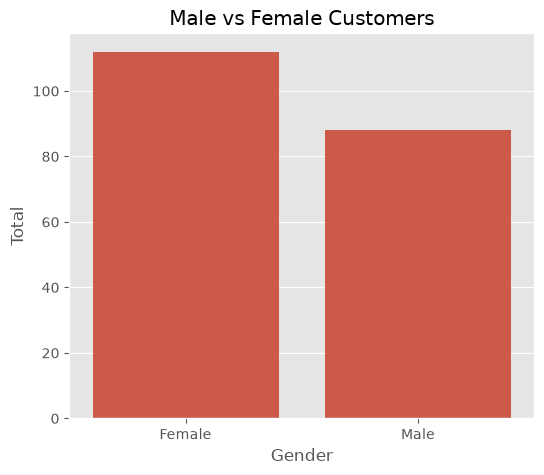

In [8]:
plt.figure(figsize=(6,5))

sns.barplot(
    x="Gender",
    y="Total",
    data=gender
)

plt.title("Male vs Female Customers")

plt.show()

**Average Age**

In [9]:
query = """

SELECT

ROUND(AVG(Age),2) AS Average_Age

FROM customers;

"""

pd.read_sql(query,conn)

,Average_Age
0,38.85


**Average Income**

In [10]:
query = """

SELECT

ROUND(AVG(Income),2) AS Average_Income

FROM customers;

"""

pd.read_sql(query,conn)

,Average_Income
0,60.56


**Average Spending Score**

In [11]:
query = """

SELECT

ROUND(AVG(Score),2) AS Average_Spending

FROM customers;

"""

pd.read_sql(query,conn)

,Average_Spending
0,50.2


**Highest Income Customers**

In [12]:
query = """

SELECT *

FROM customers

ORDER BY Income DESC

LIMIT 10;

"""

pd.read_sql(query,conn)

,CustomerID,Gender,Age,Income,Score
0,199,Male,32,137,18
1,200,Male,30,137,83
2,197,Female,45,126,28
3,198,Male,32,126,74
4,195,Female,47,120,16
5,196,Female,35,120,79
6,193,Male,33,113,8
7,194,Female,38,113,91
8,189,Female,41,103,17
9,190,Female,36,103,85


**Highest Spending Customers**

In [13]:
query = """

SELECT *

FROM customers

ORDER BY Score DESC

LIMIT 10;

"""

pd.read_sql(query,conn)

,CustomerID,Gender,Age,Income,Score
0,12,Female,35,19,99
1,20,Female,35,23,98
2,146,Male,28,77,97
3,186,Male,30,99,97
4,128,Male,40,71,95
5,168,Female,33,86,95
6,8,Female,23,18,94
7,142,Male,32,75,93
8,164,Female,31,81,93
9,34,Male,18,33,92


**Young Customers**

In [14]:
query = """

SELECT *

FROM customers

WHERE Age < 25;

"""

young = pd.read_sql(query,conn)

young.head()

,CustomerID,Gender,Age,Income,Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,6,Female,22,17,76


**Senior Customers**

In [15]:
query = """

SELECT *

FROM customers

WHERE Age > 50;

"""

pd.read_sql(query,conn)

,CustomerID,Gender,Age,Income,Score
0,9,Male,64,19,3
1,11,Male,67,19,14
2,13,Female,58,20,15
3,19,Male,52,23,29
4,25,Female,54,28,14
5,31,Male,60,30,4
6,33,Male,53,33,4
7,41,Female,65,38,35
8,54,Male,59,43,60
9,57,Female,51,44,50


**Income Groups**

In [16]:
query = """

SELECT

CASE

WHEN Income <40 THEN 'Low'

WHEN Income BETWEEN 40 AND 70 THEN 'Medium'

ELSE 'High'

END AS Income_Group,

COUNT(*) AS Customers

FROM customers

GROUP BY Income_Group;

"""

income = pd.read_sql(query,conn)

income

,Income_Group,Customers
0,High,74
1,Low,46
2,Medium,80


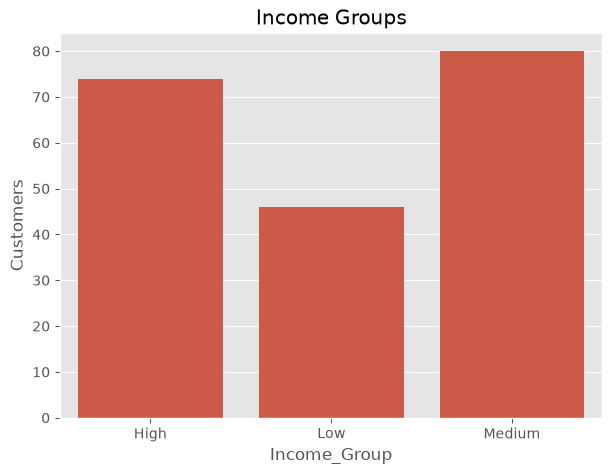

In [17]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=income,
    x="Income_Group",
    y="Customers"
)

plt.title("Income Groups")

plt.show()

**Spending Groups**

In [18]:
query = """

SELECT

CASE

WHEN Score<40 THEN 'Low'

WHEN Score BETWEEN 40 AND 70 THEN 'Medium'

ELSE 'High'

END AS Spending_Group,

COUNT(*) AS Customers

FROM customers

GROUP BY Spending_Group;

"""

spending = pd.read_sql(query,conn)

spending

,Spending_Group,Customers
0,High,54
1,Low,59
2,Medium,87


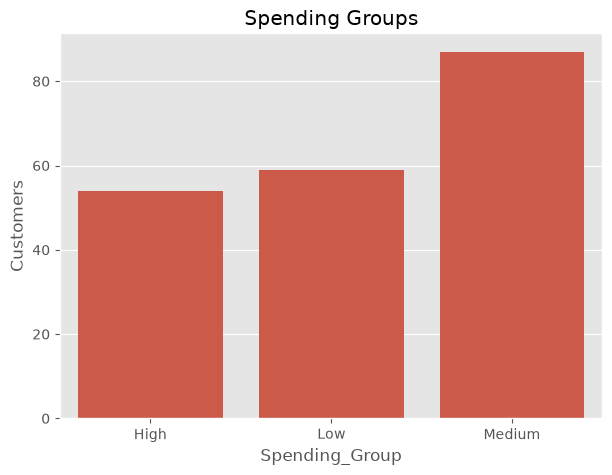

In [19]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=spending,
    x="Spending_Group",
    y="Customers"
)

plt.title("Spending Groups")

plt.show()

**Gender-wise Average Income**

In [20]:
query = """

SELECT

Gender,

ROUND(AVG(Income),2) AS Average_Income

FROM customers

GROUP BY Gender;

"""

gender_income = pd.read_sql(query,conn)

gender_income

,Gender,Average_Income
0,Female,59.25
1,Male,62.23


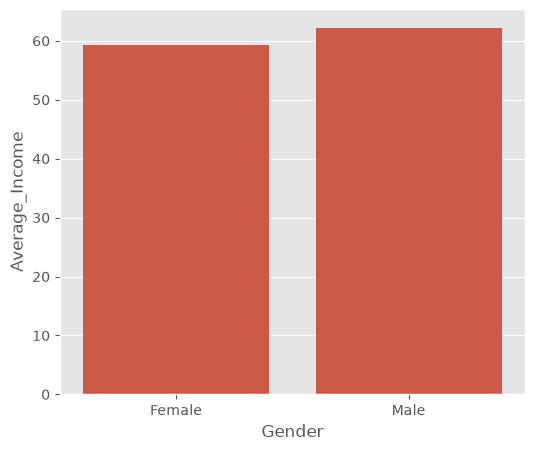

In [21]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=gender_income,
    x="Gender",
    y="Average_Income"
)

plt.show()

**Gender-wise Spending**

In [22]:
query = """

SELECT

Gender,

ROUND(AVG(Score),2) AS Spending

FROM customers

GROUP BY Gender;

"""

gender_score = pd.read_sql(query,conn)

gender_score

,Gender,Spending
0,Female,51.53
1,Male,48.51


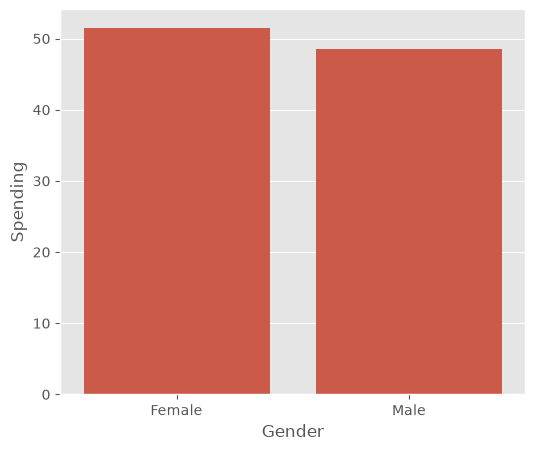

In [23]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=gender_score,
    x="Gender",
    y="Spending"
)

plt.show()

**Age Groups**

In [24]:
query = """

SELECT

CASE

WHEN Age<20 THEN 'Teen'

WHEN Age BETWEEN 20 AND 35 THEN 'Young Adult'

WHEN Age BETWEEN 36 AND 50 THEN 'Adult'

ELSE 'Senior'

END AS Age_Group,

COUNT(*) AS Customers

FROM customers

GROUP BY Age_Group;

"""

age = pd.read_sql(query,conn)

age

,Age_Group,Customers
0,Adult,62
1,Senior,40
2,Teen,12
3,Young Adult,86


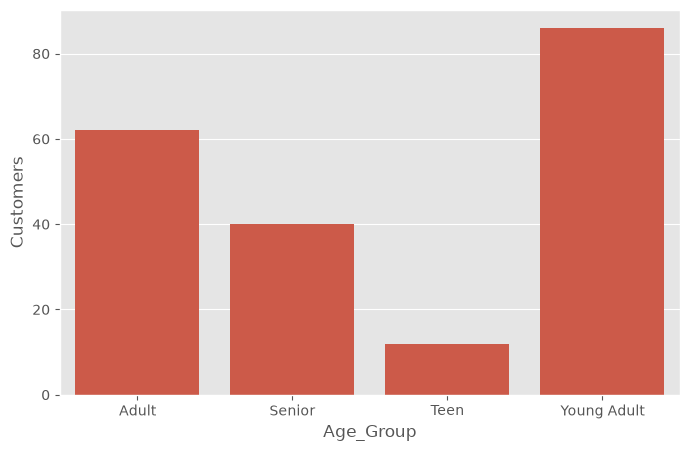

In [25]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=age,
    x="Age_Group",
    y="Customers"
)

plt.show()

**Top 5 Highest Income Customers**

In [26]:
query = """

SELECT

CustomerID,

Income,

Score

FROM customers

ORDER BY Income DESC

LIMIT 5;

"""

pd.read_sql(query,conn)

,CustomerID,Income,Score
0,199,137,18
1,200,137,83
2,197,126,28
3,198,126,74
4,195,120,16


**Customers with High Income & High Spending**

In [27]:
query = """

SELECT *

FROM customers

WHERE Income>70

AND Score>70;

"""

vip = pd.read_sql(query,conn)

vip

,CustomerID,Gender,Age,Income,Score
0,128,Male,40,71,95
1,130,Male,38,71,75
2,132,Male,39,71,75
3,134,Female,31,72,71
4,136,Female,29,73,88
5,138,Male,32,73,73
6,140,Female,35,74,72
7,142,Male,32,75,93
8,144,Female,32,76,87
9,146,Male,28,77,97


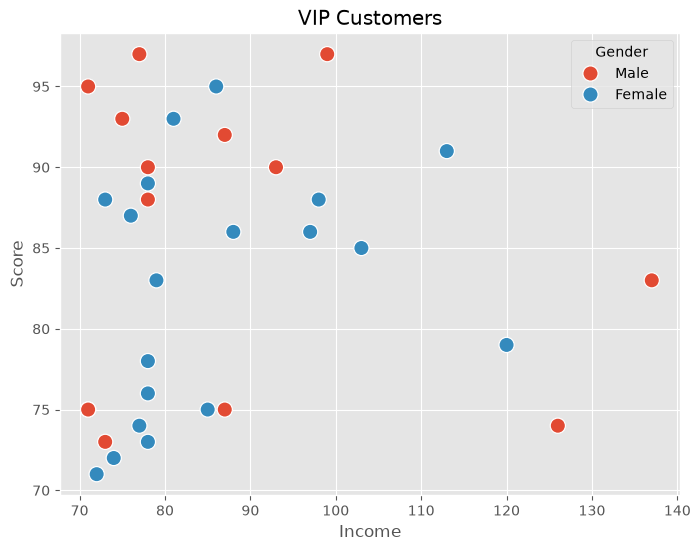

In [28]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=vip,
    x="Income",
    y="Score",
    hue="Gender",
    s=120
)

plt.title("VIP Customers")

plt.show()

**Save SQL Results**

In [29]:
vip.to_csv(
    "../data/vip_customers.csv",
    index=False
)

print("VIP customers saved successfully!")

VIP customers saved successfully!


In [30]:
conn.close()

**Business Insights
------------------**

1. Female and male customer counts are balanced.
2. High-income customers are not always high spenders.
3. VIP customers are ideal targets for premium marketing.
4. Medium-income customers form the largest customer segment.
5. Spending behavior varies significantly across age groups.
6. SQL enables quick extraction of actionable business insights.